In [1]:
!pip install opencv-python numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Step 2: Do sample images load karein
img1_path = "image1.jpg"
img2_path = "image2.jpg"

img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)

# Verify karein ki dono images successfully load hui hain ya nahi
if img1 is None:
    raise FileNotFoundError(f"'{img1_path}' nahi mili. Kripya file path check karein.")
if img2 is None:
    raise FileNotFoundError(f"'{img2_path}' nahi mili. Kripya file path check karein.")

print("Original Image 1 shape (H, W, C):", img1.shape)
print("Original Image 2 shape (H, W, C):", img2.shape)

Original Image 1 shape (H, W, C): (441, 694, 3)
Original Image 2 shape (H, W, C): (441, 693, 3)


In [4]:
# Step 3: Agar dono images ke dimensions alag hain to resize karein
# Note: cv2.resize() mein size (width, height) tuple mein diya jata hai
target_height, target_width = img1.shape[:2]

if img2.shape[:2] != (target_height, target_width):
    img2 = cv2.resize(img2, (target_width, target_height), interpolation=cv2.INTER_AREA)
    print("Image 2 ko Image 1 ke dimensions par resize kiya gaya:", img2.shape)

# Step 4: Weighted image blending perform karein
# Formula: blended = img1 * alpha + img2 * beta + gamma
alpha = 0.6   # Image 1 ka weight (60%)
beta = 0.4    # Image 2 ka weight (40%)
gamma = 0.0   # Brightness scalar offset

blended_img = cv2.addWeighted(img1, alpha, img2, beta, gamma)

# Step 5: Input aur blended output images save karein
cv2.imwrite("input_image_1.png", img1)
cv2.imwrite("input_image_2.png", img2)
cv2.imwrite("blended_output.png", blended_img)
print("Images save ho gayi hain: input_image_1.png, input_image_2.png, blended_output.png")

Image 2 ko Image 1 ke dimensions par resize kiya gaya: (441, 694, 3)
Images save ho gayi hain: input_image_1.png, input_image_2.png, blended_output.png


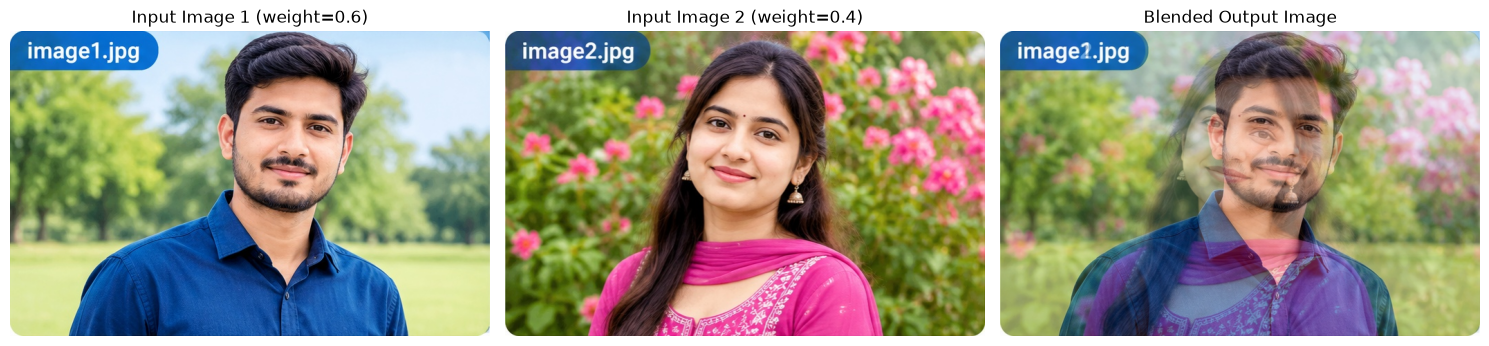

In [5]:
# Step 6: Verification ke liye teeno images ko side-by-side display karein
# OpenCV BGR format mein read karta hai, isliye matplotlib ke liye RGB mein convert karein
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
blended_rgb = cv2.cvtColor(blended_img, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img1_rgb)
axes[0].set_title(f"Input Image 1 (weight={alpha})")
axes[0].axis("off")

axes[1].imshow(img2_rgb)
axes[1].set_title(f"Input Image 2 (weight={beta})")
axes[1].axis("off")

axes[2].imshow(blended_rgb)
axes[2].set_title("Blended Output Image")
axes[2].axis("off")

plt.tight_layout()
plt.show()